In [1]:
%pip install kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [kagglehub]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

100%|██████████| 66.0M/66.0M [00:01<00:00, 36.3MB/s]

Extracting files...


Path to dataset files: /home/filonoa1/.cache/kagglehub/datasets/mlg-ulb/creditcardfraud/versions/3


import pandas as pd
import matplotlib.pyplot as plt
import os

In [3]:
df = pd.read_csv(os.path.join(path, "creditcard.csv"))
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Train XGBOOST

In [4]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=["Time", "Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=2
)



In [5]:
df = df.drop_duplicates()

In [6]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),  # imbalance handling
    eval_metric="aucpr",
    random_state=42
)

model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'aucpr'


In [7]:
# predict

threshold = 0.5
y_proba = model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= threshold).astype(int)

              precision    recall  f1-score   support

   Non-fraud       1.00      1.00      1.00     56864
       Fraud       0.89      0.84      0.86        98

    accuracy                           1.00     56962
   macro avg       0.95      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962

Confusion matrix:
[[56854    10]
 [   16    82]]
PR-AUC: 0.8764188531331422


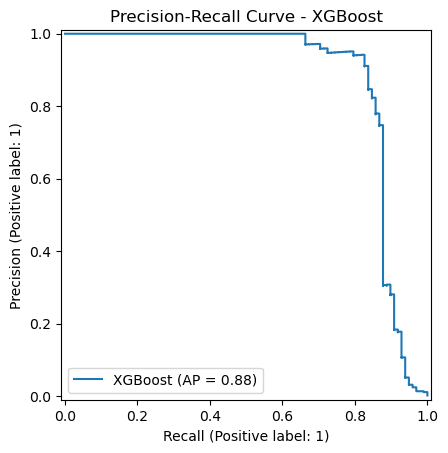

In [8]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    average_precision_score, PrecisionRecallDisplay
)
import matplotlib.pyplot as plt

# evaluate

print(classification_report(y_test, y_pred, target_names=["Non-fraud", "Fraud"]))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("PR-AUC:", average_precision_score(y_test, y_proba))

PrecisionRecallDisplay.from_predictions(y_test, y_proba, name="XGBoost")
plt.title("Precision-Recall Curve - XGBoost")
plt.show()

# K-fold validation

In [9]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score
import numpy as np

X_full = df.drop(columns=["Time", "Class"])
y_full = df["Class"]

n_folds = 5

skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

pr_auc_scores = []
precision_scores = []
recall_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_full, y_full), 1):
    X_train_fold, X_test_fold = X_full.iloc[train_idx], X_full.iloc[test_idx]
    y_train_fold, y_test_fold = y_full.iloc[train_idx], y_full.iloc[test_idx]

    # scale_pos_weight computed PER FOLD — avoids leaking global class ratio info
    spw = (y_train_fold == 0).sum() / (y_train_fold == 1).sum()

    model = XGBClassifier(
        n_estimators=100,
        scale_pos_weight=spw,
        eval_metric="aucpr",
        random_state=42
    )
    model.fit(X_train_fold, y_train_fold)

    y_proba_fold = model.predict_proba(X_test_fold)[:, 1]
    y_pred_fold = (y_proba_fold >= 0.5).astype(int)

    pr_auc = average_precision_score(y_test_fold, y_proba_fold)
    prec = precision_score(y_test_fold, y_pred_fold)
    rec = recall_score(y_test_fold, y_pred_fold)
    f1 = f1_score(y_test_fold, y_pred_fold)

    pr_auc_scores.append(pr_auc)
    precision_scores.append(prec)
    recall_scores.append(rec)
    f1_scores.append(f1)

    print(f"Fold {fold}: PR-AUC={pr_auc:.4f}  Precision={prec:.4f}  Recall={rec:.4f}  F1={f1:.4f}")

print("\n--- Summary across folds ---")
print(f"PR-AUC:    {np.mean(pr_auc_scores):.4f} ± {np.std(pr_auc_scores):.4f}")
print(f"Precision: {np.mean(precision_scores):.4f} ± {np.std(precision_scores):.4f}")
print(f"Recall:    {np.mean(recall_scores):.4f} ± {np.std(recall_scores):.4f}")
print(f"F1:        {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")
    


Fold 1: PR-AUC=0.8392  Precision=0.9186  Recall=0.8316  F1=0.8729
Fold 2: PR-AUC=0.8492  Precision=0.9390  Recall=0.8191  F1=0.8750
Fold 3: PR-AUC=0.8279  Precision=0.8987  Recall=0.7553  F1=0.8208
Fold 4: PR-AUC=0.8316  Precision=0.9070  Recall=0.8211  F1=0.8619
Fold 5: PR-AUC=0.8674  Precision=0.9512  Recall=0.8211  F1=0.8814

--- Summary across folds ---
PR-AUC:    0.8431 ± 0.0142
Precision: 0.9229 ± 0.0196
Recall:    0.8096 ± 0.0275
F1:        0.8624 ± 0.0217


In [10]:
import pandas as pd

# Take all fraud cases (only 492, keep them all) + a random sample of non-fraud
fraud_sample = df[df["Class"] == 1]
nonfraud_sample = df[df["Class"] == 0].sample(n=5000, random_state=42)  # adjust size as needed

sample_df = pd.concat([fraud_sample, nonfraud_sample]).reset_index(drop=True)

X_sample = sample_df.drop(columns="Class")
y_sample = sample_df["Class"]

print(sample_df["Class"].value_counts())

Class
0    5000
1     473
Name: count, dtype: int64


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_sample_scaled = scaler.fit_transform(X_sample)

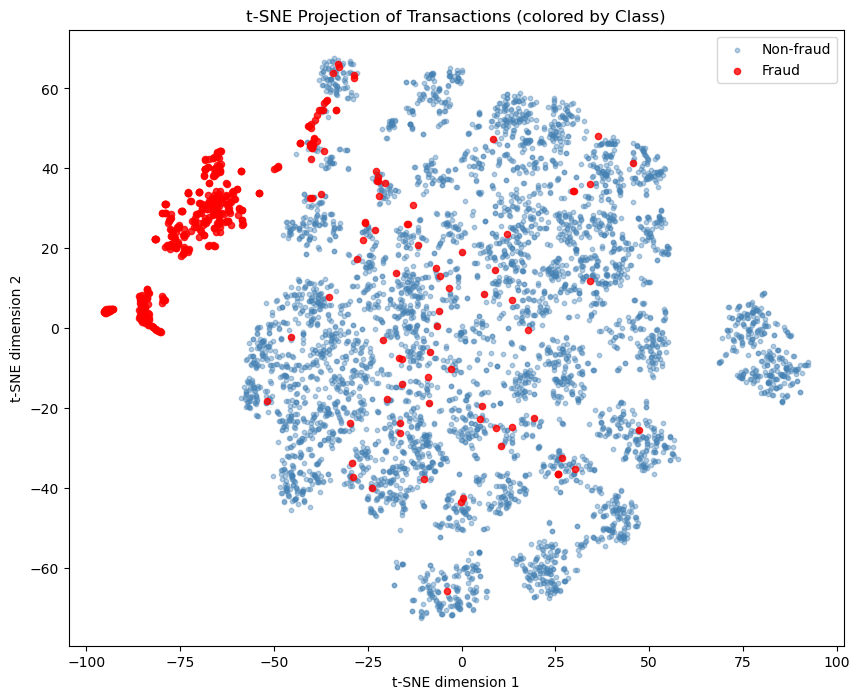

In [15]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_sample_scaled)

plt.figure(figsize=(10, 8))
plt.scatter(X_tsne[y_sample == 0, 0], X_tsne[y_sample == 0, 1],
            c="steelblue", label="Non-fraud", alpha=0.4, s=10)
plt.scatter(X_tsne[y_sample == 1, 0], X_tsne[y_sample == 1, 1],
            c="red", label="Fraud", alpha=0.8, s=20)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE Projection of Transactions (colored by Class)")
plt.legend()
plt.show()

In [16]:
# fraud points that fall in the separated upper-left region (adjust bounds to your plot)
fraud_mask = (y_sample == 1).values
in_region = (X_tsne[:, 0] < -45) & fraud_mask
print(in_region.sum(), "of", fraud_mask.sum(), "fraud points in the separated region")

367 of 473 fraud points in the separated region
